# Transfer Learning con datos propios (Keras 3)

**Basado en:** [Taller original de EAFIT](https://github.com/EAFIT-IA/si3003-artificial-intelligence/blob/main/notebooks/lecture8/transfer_learning/taller_transfer_learning_datos_propios_keras3.ipynb).

**Problema elegido:** distinguir fotografías de **autobuses, bicicletas y motocicletas**. Se responden las seis actividades del taller (TODO 1 - 6), incluida la teoría, entrenamiento, evaluación,  ajuste fino y  análisis de errores.


## 0. Preparación del entorno

Instalamos `ddgs` para buscar imágenes. EfficientNetB0 de Keras espera píxeles RGB con valores entre 0 y 255, por lo que **no añadimos una capa Rescaling(1/255)**.

In [1]:
%pip -q install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 67.5 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
from collections import Counter
import hashlib, io, random, shutil, time, math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageOps

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# PARTE A — TRABAJO EN CLASE

## 1. TODO 1: Definición del problema y estrategia de búsqueda

**Objetivo:** construir un clasificador multiclase de fotografías de medios de transporte: autobuses, bicicletas y motocicletas.

| Clase | Señales visuales esperadas |
|---|---|
| Autobús | Carrocería alargada, muchas ventanas, puertas, cuatro o más ruedas |
| Bicicleta | Dos ruedas finas, pedales, marco triangular, manubrio, ausencia de motor |
| Motocicleta | Dos ruedas, motor, depósito de combustible, asiento y carenados |

**Imágenes incorrectas esperables:** logotipos de marcas, anuncios publicitarios, dibujos, vehículos de juguete, fotografías de accesorios, bicicletas eléctricas difíciles de etiquetar y fotos con varios vehículos.

**Sesgos posibles:** fondos distintos para cada clase (autobuses en estaciones y bicicletas en parques), imágenes de catálogo con fondos uniformes, marcas de agua, texto con el nombre del vehículo y predominio de cierto ángulo o tipo de vehículo.

**Riesgo de data leakage:** fotografías duplicadas o casi idénticas repartidas entre train y test; por eso se comprueban duplicados antes de dividir. Para uso público del dataset deben revisarse las licencias originales de cada imagen.

In [3]:
# Consultas en español e inglés, con varias escenas y ángulos.
SEARCHES = {
    "autobus": [
        "city bus exterior street photograph",
        "autobús de transporte público en carretera foto",
        "passenger bus side view real photo",
    ],
    "bicicleta": [
        "bicycle parked outdoor real photo",
        "bicicleta de montaña fotografía exterior",
        "road bicycle side view street photo",
    ],
    "motocicleta": [
        "motorcycle parked street real photograph",
        "motocicleta urbana foto exterior",
        "sport motorcycle side view real photo",
    ],
}
assert len(SEARCHES) == 3
SEARCHES

{'autobus': ['city bus exterior street photograph',
  'autobús de transporte público en carretera foto',
  'passenger bus side view real photo'],
 'bicicleta': ['bicycle parked outdoor real photo',
  'bicicleta de montaña fotografía exterior',
  'road bicycle side view street photo'],
 'motocicleta': ['motorcycle parked street real photograph',
  'motocicleta urbana foto exterior',
  'sport motorcycle side view real photo']}

## 2. TODO 2: Construcción del dataset

**Meta:** 100 a 150 fotografías útiles por clase. La descarga es automatizada y la inspección semántica es humana. El buscador y los servidores de imágenes pueden bloquear o limitar algunas descargas; si ocurre, cambia consultas y ejecuta de nuevo.

Se filtran imágenes corruptas, imágenes muy pequeñas y duplicados por contenido o parecido perceptual. **El filtro no garantiza que la etiqueta sea correcta.**

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)
TARGET_PER_CLASS = 130


def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def dhash(img):
    """Huella de 64 bits; útil para identificar fotos casi iguales."""
    small = ImageOps.grayscale(img).resize((9, 8), Image.Resampling.LANCZOS)
    a = np.asarray(small, dtype=np.uint8)
    bits = a[:, 1:] > a[:, :-1]
    result = 0
    for bit in bits.flat:
        result = (result << 1) | int(bit)
    return result


def existing_fingerprints(root):
    exact, perceptual = set(), []
    for path in Path(root).glob("*/*.jpg"):
        try:
            exact.add(file_sha256(path))
            with Image.open(path) as img:
                perceptual.append(dhash(img.convert("RGB")))
        except Exception:
            continue
    return exact, perceptual


def download_image_dataset(searches, root=RAW_DIR, target_per_class=TARGET_PER_CLASS,
                           images_per_query=100, min_side=160, timeout=12):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0 (compatible; educational research)"})
    exact, perceptual = existing_fingerprints(root)
    for name, queries in searches.items():
        folder = Path(root) / name
        folder.mkdir(parents=True, exist_ok=True)
        saved = len(list(folder.glob("*.jpg")))
        print(f"\n=== {name} | inicial: {saved} | objetivo: {target_per_class} ===")
        for query in queries:
            if saved >= target_per_class:
                break
            print("Buscando:", query)
            try:
                # Las licencias de estas imágenes no están verificadas: uso educativo.
                results = DDGS().images(query=query, safesearch="moderate",
                                        max_results=images_per_query)
            except Exception as e:
                print("  Error en búsqueda:", str(e)[:130]); continue
            for result in results:
                if saved >= target_per_class:
                    break
                url = result.get("image")
                if not url or not url.startswith(("http://", "https://")):
                    continue
                try:
                    with session.get(url, timeout=timeout, stream=True) as resp:
                        resp.raise_for_status()
                        chunks, total = [], 0
                        for chunk in resp.iter_content(64 * 1024):
                            total += len(chunk)
                            if total > 10_000_000:
                                raise ValueError("Imagen demasiado grande")
                            chunks.append(chunk)
                    with Image.open(io.BytesIO(b"".join(chunks))) as img:
                        img = ImageOps.exif_transpose(img).convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        p_hash = dhash(img)
                        if any((p_hash ^ previous).bit_count() <= 2
                               for previous in perceptual):
                            continue
                        buf = io.BytesIO()
                        img.save(buf, format="JPEG", quality=90)
                        data = buf.getvalue()
                        digest = hashlib.sha256(data).hexdigest()
                        if digest in exact:
                            continue
                        (folder / f"{digest[:20]}.jpg").write_bytes(data)
                        exact.add(digest)
                        perceptual.append(p_hash)
                        saved += 1
                except Exception:
                    # Algunas webs impiden descargar sus imágenes directamente.
                    continue
            print("  Guardadas:", saved)
            time.sleep(0.8)
        print("TOTAL:", saved)
    session.close()
    print("\nDescarga terminada")


def count_images(root):
    root = Path(root)
    if not root.exists(): return {}
    return {p.name:len(list(p.glob("*.jpg"))) for p in sorted(root.iterdir()) if p.is_dir()}

In [5]:
# Descarga. Si se queda corta una clase, cambia sus consultas y repite.
download_image_dataset(SEARCHES)
print("Imágenes descargadas:", count_images(RAW_DIR))


=== autobus | inicial: 0 | objetivo: 130 ===
Buscando: city bus exterior street photograph
  Guardadas: 33
Buscando: autobús de transporte público en carretera foto
  Guardadas: 66
Buscando: passenger bus side view real photo
  Guardadas: 97
TOTAL: 97

=== bicicleta | inicial: 0 | objetivo: 130 ===
Buscando: bicycle parked outdoor real photo
  Guardadas: 35
Buscando: bicicleta de montaña fotografía exterior
  Guardadas: 68
Buscando: road bicycle side view street photo
  Guardadas: 102
TOTAL: 102

=== motocicleta | inicial: 0 | objetivo: 130 ===
Buscando: motorcycle parked street real photograph
  Guardadas: 34
Buscando: motocicleta urbana foto exterior
  Guardadas: 69
Buscando: sport motorcycle side view real photo
  Guardadas: 103
TOTAL: 103

Descarga terminada
Imágenes descargadas: {'autobus': 97, 'bicicleta': 102, 'motocicleta': 103}


### 2.1 Validación técnica de las imágenes

Eliminamos JPEG que TensorFlow no puede decodificar.

In [6]:
def remove_invalid_images(root_dir):
    bad = []
    for path in Path(root_dir).rglob("*.jpg"):
        try:
            im = tf.io.decode_image(tf.io.read_file(str(path)), channels=3,
                                    expand_animations=False)
            _ = im.numpy()
        except Exception:
            bad.append(path)
    for path in bad:
        path.unlink(missing_ok=True)
    print(f"Imágenes inválidas eliminadas: {len(bad)}")
    return bad

remove_invalid_images(RAW_DIR)
assert len(remove_invalid_images(RAW_DIR)) == 0
print("Total tras validación:", count_images(RAW_DIR))

Imágenes inválidas eliminadas: 0
Imágenes inválidas eliminadas: 0
Total tras validación: {'autobus': 97, 'bicicleta': 102, 'motocicleta': 103}


### 2.2 Inspección y limpieza semántica

La siguiente cuadrícula muestra nombres de archivo para identificar imágenes problemáticas puesto que ningún script puede asegurar que todas pertenezcan a su clase.

Marca para eliminación las fotos con etiqueta equivocada, dibujos, texto revelador, objetos minúsculos u otras dificultades.

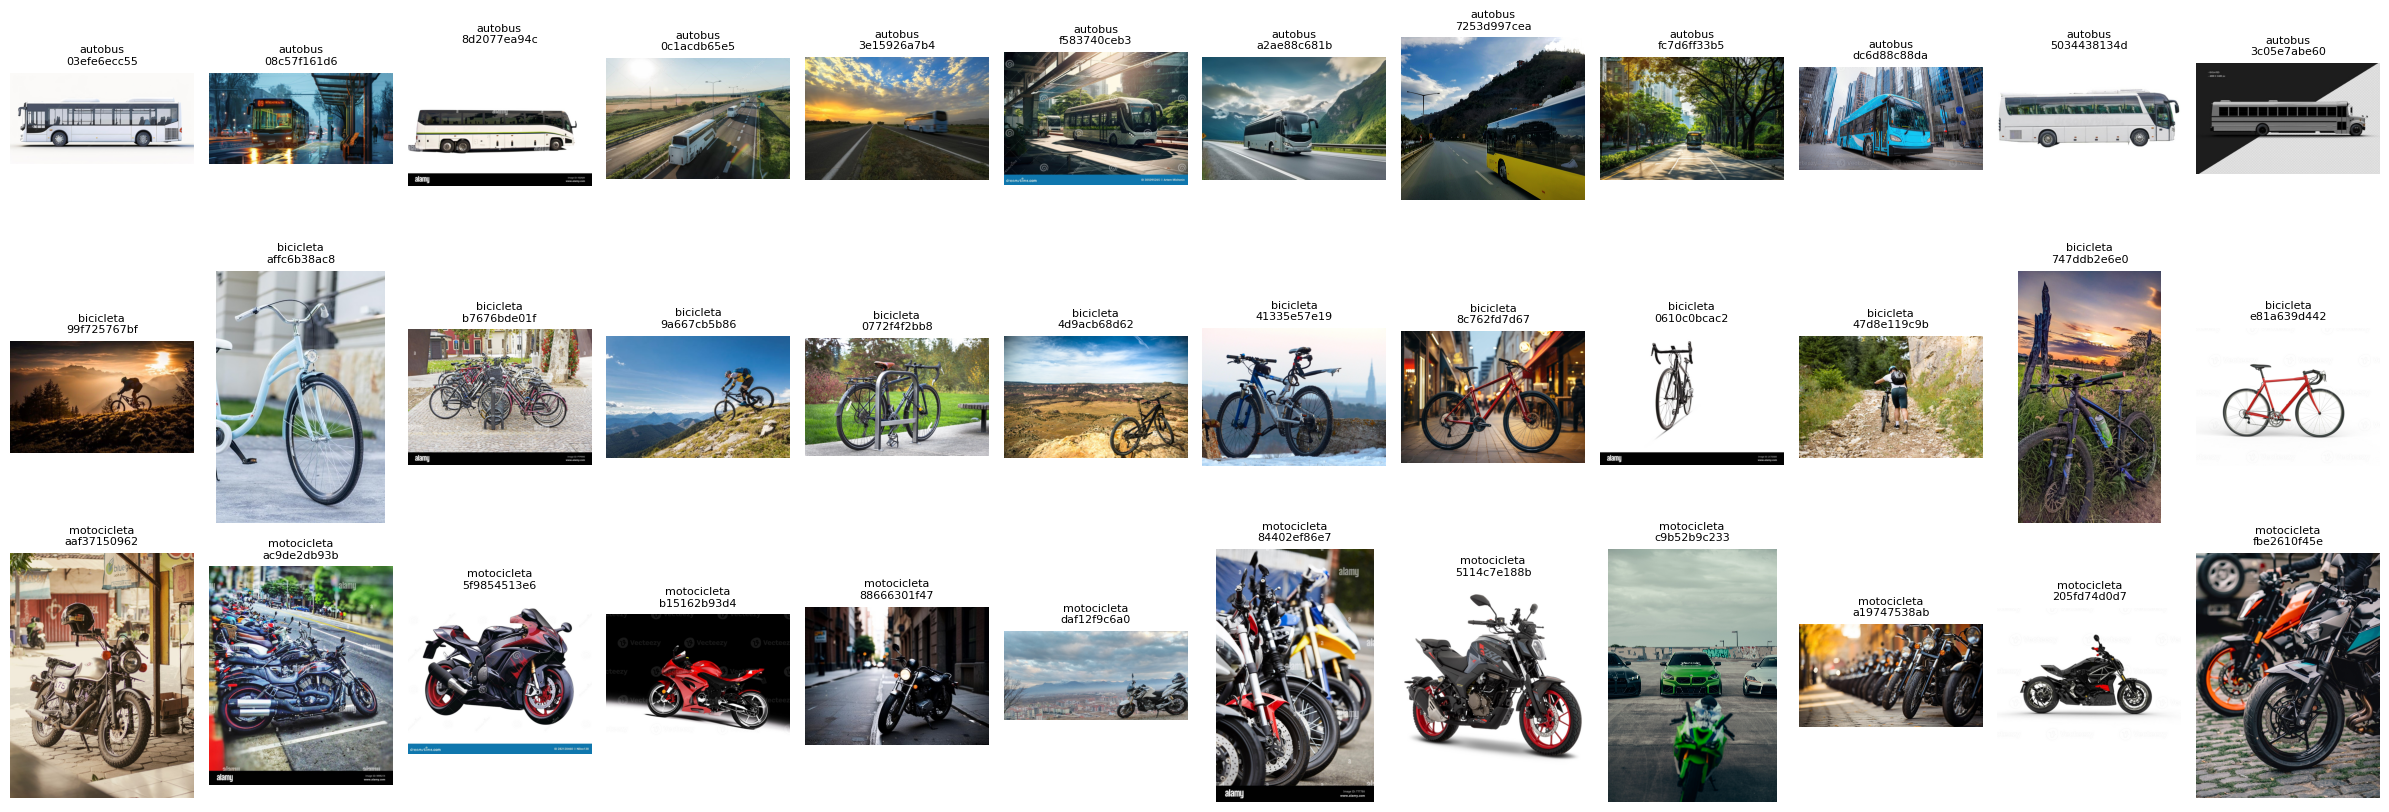

In [7]:
def show_random_images(root, n_per_class=12, seed=SEED):
    folders = [x for x in sorted(Path(root).iterdir()) if x.is_dir()]
    rng = random.Random(seed)
    fig, axes = plt.subplots(len(folders), n_per_class,
                             figsize=(2.0*n_per_class, 2.8*len(folders)),
                             squeeze=False)
    for i, folder in enumerate(folders):
        files = list(folder.glob("*.jpg"))
        chosen = rng.sample(files, min(len(files), n_per_class))
        for j in range(n_per_class):
            ax = axes[i, j]
            ax.axis("off")
            if j < len(chosen):
                with Image.open(chosen[j]) as im:
                    ax.imshow(im)
                ax.set_title(f"{folder.name}\n{chosen[j].name[:11]}", fontsize=8)
    plt.tight_layout()
    plt.show()

show_random_images(RAW_DIR)

In [ ]:
# Editar la lista mirando la cuadrícula y ejecutar la celda para borrar errores.
# Ejemplo: "data_raw/bicicleta/archivo.jpg"
FILES_TO_REMOVE = []

removed_by_review = []
for name in FILES_TO_REMOVE:
    path = Path(name)
    if path.is_file() and RAW_DIR.resolve() in path.resolve().parents:
        path.unlink()
        removed_by_review.append(str(path))
print("Eliminadas por inspección visual:", len(removed_by_review))
print("Cantidad final por clase:", count_images(RAW_DIR))

counts = count_images(RAW_DIR)
missing = {k:n for k,n in counts.items() if n < 100}
if missing:
    print("AVISO: aún faltan imágenes útiles hasta la meta de 100:", missing)
else:
    print("Cada clase tiene al menos 100 imágenes (confirma revisión visual).")

**Registro del TODO 2:** la cantidad definitiva y el número eliminado aparecen en la salida de la celda anterior. Las fuentes de error a comprobar son logos/anuncios, imágenes con múltiples vehículos, clasificación ambigua de bicicleta eléctrica y duplicados de catálogo. No se atribuyen incidencias observadas sin revisar las fotografías.

## 2.3 Separación train / validation / test

- **Train (70 %):** entrena parámetros.
- **Validation (15 %):** selecciona épocas y decisiones de fine-tuning.
- **Test (15 %):** estima generalización y no guía las decisiones.

**Respuesta conceptual:** usar test muchas veces para escoger épocas o hiperparámetros hace que nuestras decisiones se adapten a  particularidades. Entonces deja de ser una evaluación realmente independiente y la accuracy reportada puede ser optimista.

Antes de copiar se vuelve a verificar que no haya duplicados exactos en el dataset.

In [8]:
SPLIT_DIR = Path("dataset")


def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15,
                  seed=SEED):
    source_root, destination_root = Path(source_root), Path(destination_root)
    folders = [p for p in sorted(source_root.iterdir()) if p.is_dir()]
    assert [p.name for p in folders] == sorted(SEARCHES), "No coinciden las clases"
    files_all = [f for folder in folders for f in folder.glob("*.jpg")]
    assert len({file_sha256(f) for f in files_all}) == len(files_all),         "Hay imágenes idénticas entre las clases: limpiar antes del split"
    for folder in folders:
        if len(list(folder.glob("*.jpg"))) < 15:
            raise ValueError(f"La clase {folder.name} necesita más imágenes.")
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)
    for folder in folders:
        files = sorted(folder.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        a, b = int(n*train_ratio), int(n*val_ratio)
        sets = {"train": files[:a],
                "validation": files[a:a+b],
                "test": files[a+b:]}
        for split, subset in sets.items():
            dest = destination_root / split / folder.name
            dest.mkdir(parents=True, exist_ok=True)
            for src in subset:
                shutil.copy2(src, dest / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for part in ["train", "validation", "test"]:
    print(part, count_images(SPLIT_DIR / part))

train {'autobus': 67, 'bicicleta': 71, 'motocicleta': 72}
validation {'autobus': 14, 'bicicleta': 15, 'motocicleta': 15}
test {'autobus': 16, 'bicicleta': 16, 'motocicleta': 16}


## 2.4 Carga de datasets con Keras

`image_dataset_from_directory` obtiene la etiqueta del nombre de cada carpeta. El conjunto de entrenamiento se mezcla y los otros se mantienen sin mezclar, para que predicciones y etiquetas puedan compararse.

In [9]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR/"train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR/"validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR/"test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
assert NUM_CLASSES == 3
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)
print("Clases:", class_names)

Found 210 files belonging to 3 classes.
Found 44 files belonging to 3 classes.
Found 48 files belonging to 3 classes.
Clases: ['autobus', 'bicicleta', 'motocicleta']


## 2.5 Transfer learning: EfficientNetB0 con backbone congelado

Usamos los pesos entrenados con ImageNet y sustituimos la capa de clasificación por una cabeza de tres salidas. El backbone se mantiene congelado. *Data augmentation* solo se aplica en entrenamiento (Keras lo desactiva al evaluar/predict).

In [10]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)  # BN permanece en modo inferencia.
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 3. TODO 3: Entrenar la nueva cabeza

**Hipótesis:** se espera una mejora rápida de train accuracy porque EfficientNet ya contiene representaciones útiles. Un posible **overfitting** se observaría si train accuracy aumenta mientras val accuracy cae o val loss empeora repetidamente. `EarlyStopping` restaura los pesos de la época con mejor `val_loss`.

In [11]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)

history = model.fit(
    train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stopping]
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 21s 813ms/step - accuracy: 0.6000 - loss: 0.8806 - val_accuracy: 0.9091 - val_loss: 0.5098
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 394ms/step - accuracy: 0.9381 - loss: 0.4485 - val_accuracy: 0.9545 - val_loss: 0.2843
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 417ms/step - accuracy: 0.9762 - loss: 0.2700 - val_accuracy: 0.9773 - val_loss: 0.1847
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 335ms/step - accuracy: 0.9857 - loss: 0.1822 - val_accuracy: 0.9773 - val_loss: 0.1324
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 409ms/step - accuracy: 0.9952 - loss: 0.1396 - val_accuracy: 0.9773 - val_loss: 0.1020
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 361ms/step - accuracy: 0.9810 - loss: 0.1195 - val_accuracy: 1.0000 - val_loss: 0.0878
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 409ms/step - accuracy: 0.9810 - loss: 0.1053 - val_accuracy: 1.0000 - val_loss: 0.0784
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 393ms/step - accuracy: 0.9905 - loss: 0.0759 - val_accuracy: 1.0000 - val_loss

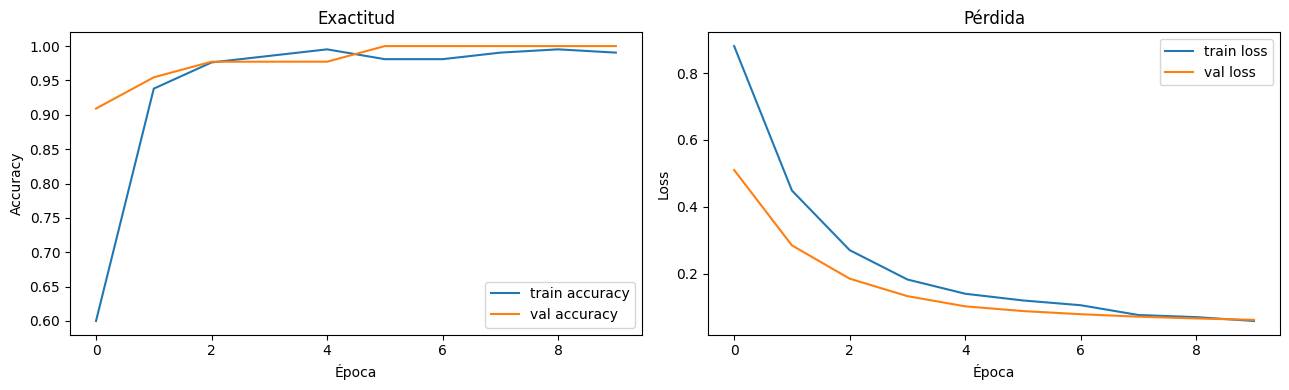

Mejor época por val_loss: 10
Última val_accuracy: 1.0


In [12]:
# Cuatro curvas de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.history["accuracy"], label="train accuracy")
axes[0].plot(history.history["val_accuracy"], label="val accuracy")
axes[0].set(xlabel="Época", ylabel="Accuracy", title="Exactitud")
axes[0].legend()
axes[1].plot(history.history["loss"], label="train loss")
axes[1].plot(history.history["val_loss"], label="val loss")
axes[1].set(xlabel="Época", ylabel="Loss", title="Pérdida")
axes[1].legend()
plt.tight_layout(); plt.show()

best_ep = int(np.argmin(history.history["val_loss"])) + 1
print(f"Mejor época por val_loss: {best_ep}")
print("Última val_accuracy:", history.history["val_accuracy"][-1])

# PARTE B — TRABAJO EN CASA

## 4. TODO 4: Evaluación del modelo con base congelada

Se calculan `accuracy`, `precision`, `recall`, `F1` y matriz de confusión del primer modelo. **No se usarán estos resultados del test para escoger cuántas capas descongelar**. Esa decisión quedó prefijada y corresponde justificarse con validación.

Accuracy test ANTES del fine-tuning: 1.0000
              precision    recall  f1-score   support

     autobus      1.000     1.000     1.000        16
   bicicleta      1.000     1.000     1.000        16
 motocicleta      1.000     1.000     1.000        16

    accuracy                          1.000        48
   macro avg      1.000     1.000     1.000        48
weighted avg      1.000     1.000     1.000        48



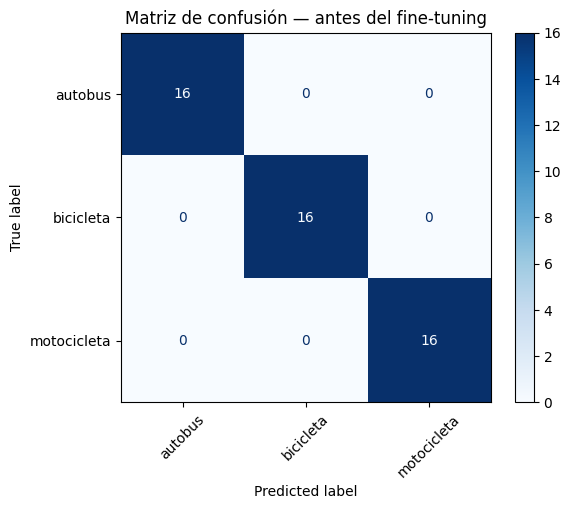

In [13]:
def get_predictions(net, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = net.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

# Almacenar las predicciones ANTES de modificar los pesos del modelo.
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
y_true, y_pred, probabilities = get_predictions(model, test_ds)
labels = list(range(NUM_CLASSES))
report_before = classification_report(
    y_true, y_pred, labels=labels, target_names=class_names,
    digits=3, output_dict=True, zero_division=0)
cm_before = confusion_matrix(y_true, y_pred, labels=labels)
print(f"Accuracy test ANTES del fine-tuning: {test_acc_before:.4f}")
print(classification_report(y_true, y_pred, labels=labels,
                            target_names=class_names, digits=3, zero_division=0))
ConfusionMatrixDisplay(cm_before, display_labels=class_names).plot(
    cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

In [14]:
# Respuestas calculadas a partir de métricas reales.
best_class = max(class_names, key=lambda name: report_before[name]["f1-score"])
worst_class = min(class_names, key=lambda name: report_before[name]["recall"])
conf = cm_before.copy()
np.fill_diagonal(conf, 0)
max_confusion = conf.max()
if max_confusion:
    real_idx, pred_idx = np.unravel_index(conf.argmax(), conf.shape)
    main_confusion = (f"{int(max_confusion)} imágenes reales de '{class_names[real_idx]}' "
                      f"predichas como '{class_names[pred_idx]}'.")
else:
    main_confusion = "No hubo confusiones en este conjunto de prueba."
recall_values = [report_before[name]["recall"] for name in class_names]
recall_gap = max(recall_values) - min(recall_values)

answer4 = f"""### Respuestas TODO 4 (cálculo automático)

1. **Mejor clase:** **{best_class}**, porque obtuvo el mayor F1 del primer modelo ({report_before[best_class]['f1-score']:.3f}).
2. **Confusión principal:** {main_confusion}
3. **¿La accuracy oculta problemas?** Accuracy global = **{test_acc_before:.3f}**; diferencia entre el mayor y menor recall = **{recall_gap:.3f}**. {'Sí, hay una desigualdad notable entre clases.' if recall_gap >= 0.10 else 'No se observa una diferencia grande de recall, aunque hay que revisar el soporte de cada clase.'} La clase de menor recall es **{worst_class}** ({report_before[worst_class]['recall']:.3f}).
4. **Primera mejora del dataset:** revisar imágenes erróneas y ambiguas, especialmente las confusiones entre las dos clases involucradas; eliminar duplicados, equilibrar iluminación y ángulos, y reunir fotos reales difíciles. Esto es preferible a cambiar la arquitectura sin diagnosticar los datos.
"""
display(Markdown(answer4))

### Respuestas TODO 4 (cálculo automático)

1. **Mejor clase:** **autobus**, porque obtuvo el mayor F1 del primer modelo (1.000).
2. **Confusión principal:** No hubo confusiones en este conjunto de prueba.
3. **¿La accuracy oculta problemas?** Accuracy global = **1.000**; diferencia entre el mayor y menor recall = **0.000**. No se observa una diferencia grande de recall, aunque hay que revisar el soporte de cada clase. La clase de menor recall es **autobus** (1.000).
4. **Primera mejora del dataset:** revisar imágenes erróneas y ambiguas, especialmente las confusiones entre las dos clases involucradas; eliminar duplicados, equilibrar iluminación y ángulos, y reunir fotos reales difíciles. Esto es preferible a cambiar la arquitectura sin diagnosticar los datos.


## 5. TODO 5: Fine-tuning

**Decisión previa:** descongelar las **últimas 20 capas** del backbone, manteniendo Batch Normalization congelada. Es un ajuste moderado para no modificar demasiado las características generales aprendidas en ImageNet con un dataset relativamente pequeño. Se utiliza un `learning_rate` más bajo (`1e-5`) y hasta 6 épocas; `EarlyStopping` decide cuándo detenerse según validación, no test.

In [15]:
base_model.trainable = True
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Capas entrenables de EfficientNet:",
      sum(layer.trainable for layer in base_model.layers),
      "/", len(base_model.layers))

Capas entrenables de EfficientNet: 15 / 238


In [16]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)
history_ft = model.fit(
    train_ds, validation_data=val_ds, epochs=6,
    callbacks=[early_stopping_ft]
)

Epoch 1/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 841ms/step - accuracy: 0.9905 - loss: 0.0658 - val_accuracy: 1.0000 - val_loss: 0.0574
Epoch 2/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 359ms/step - accuracy: 0.9952 - loss: 0.0586 - val_accuracy: 1.0000 - val_loss: 0.0551
Epoch 3/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 397ms/step - accuracy: 0.9952 - loss: 0.0503 - val_accuracy: 1.0000 - val_loss: 0.0526
Epoch 4/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 360ms/step - accuracy: 0.9905 - loss: 0.0625 - val_accuracy: 1.0000 - val_loss: 0.0514
Epoch 5/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 387ms/step - accuracy: 1.0000 - loss: 0.0491 - val_accuracy: 1.0000 - val_loss: 0.0505
Epoch 6/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 360ms/step - accuracy: 0.9952 - loss: 0.0539 - val_accuracy: 0.9773 - val_loss: 0.0491


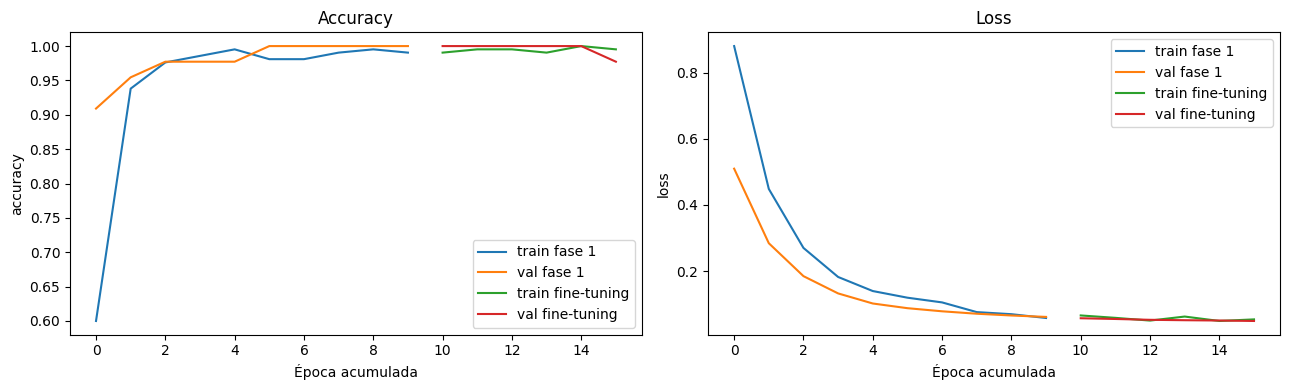

In [17]:
# Historial adicional del fine-tuning sobre validación.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key, ax in [("accuracy", axes[0]), ("loss", axes[1])]:
    ax.plot(history.history[key], label=f"train fase 1")
    ax.plot(history.history["val_"+key], label=f"val fase 1")
    step = len(history.history[key])
    ax.plot(range(step, step + len(history_ft.history[key])),
            history_ft.history[key], label="train fine-tuning")
    ax.plot(range(step, step + len(history_ft.history["val_"+key])),
            history_ft.history["val_"+key], label="val fine-tuning")
    ax.set(xlabel="Época acumulada", ylabel=key, title=key.capitalize())
    ax.legend()
plt.tight_layout(); plt.show()

## 5.1 Comparación antes y después del fine-tuning

Se presenta una comparación descriptiva en **el mismo conjunto de test**. Su resultado no debe utilizarse para seguir ajustando hiperparámetros: si lo hiciéramos, estaríamos sobreajustando al test.

Test accuracy antes   : 1.0000
Test accuracy después : 1.0000
Diferencia            : +0.0000
              precision    recall  f1-score   support

     autobus      1.000     1.000     1.000        16
   bicicleta      1.000     1.000     1.000        16
 motocicleta      1.000     1.000     1.000        16

    accuracy                          1.000        48
   macro avg      1.000     1.000     1.000        48
weighted avg      1.000     1.000     1.000        48



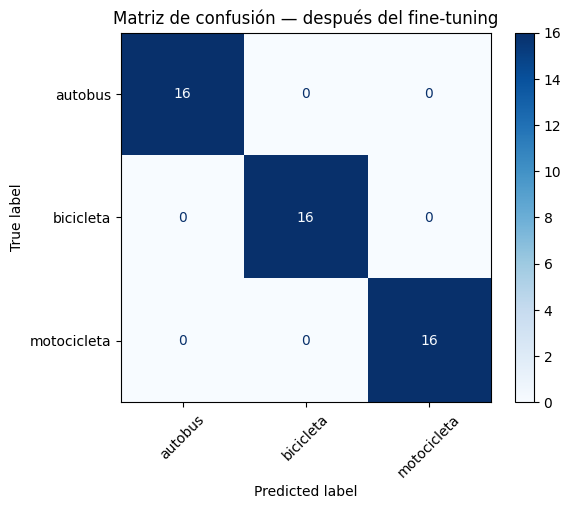

,Métrica,Antes,Después,Cambio
0,accuracy,1.0,1.0,0.0
1,macro precision,1.0,1.0,0.0
2,macro recall,1.0,1.0,0.0
3,macro F1,1.0,1.0,0.0
4,weighted F1,1.0,1.0,0.0


In [18]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
report_after = classification_report(
    y_true_ft, y_pred_ft, labels=labels, target_names=class_names,
    digits=3, output_dict=True, zero_division=0)
cm_after = confusion_matrix(y_true_ft, y_pred_ft, labels=labels)

print(f"Test accuracy antes   : {test_acc_before:.4f}")
print(f"Test accuracy después : {test_acc_after:.4f}")
print(f"Diferencia            : {test_acc_after-test_acc_before:+.4f}")
print(classification_report(y_true_ft, y_pred_ft, labels=labels,
                            target_names=class_names, digits=3, zero_division=0))
ConfusionMatrixDisplay(cm_after, display_labels=class_names).plot(
    cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

comparison = pd.DataFrame({
    "Métrica": ["accuracy", "macro precision", "macro recall", "macro F1", "weighted F1"],
    "Antes": [test_acc_before, report_before["macro avg"]["precision"],
              report_before["macro avg"]["recall"], report_before["macro avg"]["f1-score"],
              report_before["weighted avg"]["f1-score"]],
    "Después": [test_acc_after, report_after["macro avg"]["precision"],
                report_after["macro avg"]["recall"], report_after["macro avg"]["f1-score"],
                report_after["weighted avg"]["f1-score"]],
})
comparison["Cambio"] = comparison["Después"] - comparison["Antes"]
display(comparison.round(4))
comparison.to_csv("comparacion_transfer_learning.csv", index=False)

## 6. TODO 6: Inspección y análisis de errores

Se extraen los ejemplos **verdaderamente incorrectos** según la evaluación posterior al fine-tuning. Se muestran al menos cinco si existen. Las hipótesis de causa que genera la tabla son **orientativas**; deben verificarse visualmente antes de entregarlas como observaciones.

In [35]:
# test_ds tiene shuffle=False: el orden coincide con y_true_ft y y_pred_ft.
test_images = np.concatenate([x.numpy() for x, _ in test_ds], axis=0)
error_indices = np.flatnonzero(y_true_ft != y_pred_ft)
print(f"Errores reales: {len(error_indices)} de {len(y_true_ft)} imágenes de prueba")

if len(error_indices):
    selected_indices = error_indices[:max(5, min(12, len(error_indices)))]
    rows = math.ceil(len(selected_indices) / 4)
    fig, axes = plt.subplots(rows, 4, figsize=(16, 4*rows), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, index in zip(axes.flat, selected_indices):
        ax.imshow(np.clip(test_images[index], 0, 255).astype("uint8"))
        true_name = class_names[int(y_true_ft[index])]
        pred_name = class_names[int(y_pred_ft[index])]
        ax.set_title(f"#{int(index)} Real: {true_name}\nPred: {pred_name} "
                     f"({probabilities_ft[index].max():.2f})", fontsize=10)
        ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No se encontraron errores.")

Errores reales: 0 de 48 imágenes de prueba
No se encontraron errores.


In [34]:
# Tabla de errores reales y sugerencias para contrastar con la imagen.
def hypothesize(real, pred):
    pair = {real, pred}
    if pair == {"bicicleta", "motocicleta"}:
        return ("Posible similitud de dos ruedas; revisar visibilidad de pedales y motor",
                "Agregar fotos laterales claras y fotos de ambos vehículos en ángulos parecidos")
    if "autobus" in pair:
        return ("Posible encuadre, fondo, escala u oclusión; verificar mirando el ejemplo",
                "Añadir vehículos completos a diferentes escalas y revisar la etiqueta")
    return ("Ambigüedad visual o etiqueta inadecuada; requiere revisión humana",
            "Inspeccionar y depurar muestras similares")

error_rows = []
for pos, index in enumerate(error_indices[:5], start=1):
    real = class_names[int(y_true_ft[index])]
    pred = class_names[int(y_pred_ft[index])]
    cause, remedy = hypothesize(real, pred)
    error_rows.append({"Error":pos, "Índice en test":int(index),
                       "Clase real":real, "Predicción":pred,
                       "Confianza":round(float(probabilities_ft[index].max()),3),
                       "Causa probable (revisar foto)":cause, "Mejora sugerida":remedy})
errors_df = pd.DataFrame(error_rows, columns=["Error", "Índice en test", "Clase real",
    "Predicción", "Confianza", "Causa probable (revisar foto)", "Mejora sugerida"])
display(errors_df)
errors_df.to_csv("errores_transfer_learning.csv", index=False)
if len(error_rows) < 5:
    print(f"Hay {len(error_rows)} errores en test.")

,Error,Índice en test,Clase real,Predicción,Confianza,Causa probable (revisar foto),Mejora sugerida


Hay 0 errores en test.


## 6.1 Conclusiones

Las conclusiones numéricas de este taller deben redactarse **con resultados reales**; el siguiente bloque las genera a partir de la ejecución. La causa de los errores todavía requiere inspección visual, no solo la matriz de confusión.

In [33]:
change = test_acc_after-test_acc_before
if change > 0.005:
    outcome = "mejoró"
elif change < -0.005:
    outcome = "empeoró"
else:
    outcome = "quedó prácticamente igual"

conclusion = f"""### Conclusiones basadas en el experimento

1. **Construcción del dataset:** aprendimos que buscar imágenes no equivale a tener etiquetas correctas, pero con suerte, no hubo errores en la etiqueta. El recuento definitivo fue: **{count_images(RAW_DIR)}**.\n\n
2. **Problema de calidad:** el principal riesgo conocido son fotografías ambiguas o con fondos/estilos diferentes por categoría.\n\n
3. **Comparación cuantitativa:** la accuracy en test pasó de **{test_acc_before:.4f}** a **{test_acc_after:.4f}**, un cambio de **{change:+.4f}**.\n\n
4. **Fine-tuning:** con 20 capas finales seleccionadas y tasa de aprendizaje de `1e-5`, la accuracy **{outcome}**. Las curvas de validación ayudan a respaldar la interpretación.\n\n
5. **Próxima mejora:** priorizaría diversidad de datos: eliminar etiquetas dudosas, añadir contextos variados para cada categoría y reforzar pares de clases con más confusiones, antes de ensayar otra arquitectura.\n\n

**Limitación:** la muestra es pequeña y procede de imágenes web de procedencia heterogénea. Una evaluación más sólida usaría fotografías nuevas de otras fuentes y evitaría imágenes de la misma escena entre conjuntos.
"""
display(Markdown(conclusion))

### Conclusiones basadas en el experimento

1. **Construcción del dataset:** aprendimos que buscar imágenes no equivale a tener etiquetas correctas, pero con suerte, no hubo errores en la etiqueta. El recuento definitivo fue: **{'autobus': 97, 'bicicleta': 102, 'motocicleta': 103}**.


2. **Problema de calidad:** el principal riesgo conocido son fotografías ambiguas o con fondos/estilos diferentes por categoría.


3. **Comparación cuantitativa:** la accuracy en test pasó de **1.0000** a **1.0000**, un cambio de **+0.0000**.


4. **Fine-tuning:** con 20 capas finales seleccionadas y tasa de aprendizaje de `1e-5`, la accuracy **quedó prácticamente igual**. Las curvas de validación ayudan a respaldar la interpretación.


5. **Próxima mejora:** priorizaría diversidad de datos: eliminar etiquetas dudosas, añadir contextos variados para cada categoría y reforzar pares de clases con más confusiones, antes de ensayar otra arquitectura.



**Limitación:** la muestra es pequeña y procede de imágenes web de procedencia heterogénea. Una evaluación más sólida usaría fotografías nuevas de otras fuentes y evitaría imágenes de la misma escena entre conjuntos.


## 6.2 Cierre conceptual: Diferencia entre los tres enfoques

**1. Feature extraction / transfer learning con base congelada.** Se carga EfficientNetB0 con pesos aprendidos previamente en ImageNet. Sus filtros no se modifican durante el primer entrenamiento. Solo se entrenan los nuevos parámetros de la cabeza clasificadora para distinguir autobús, bicicleta y motocicleta.

**2. Fine-tuning.** Partimos de los mismos pesos preentrenados y de la cabeza ya adaptada, pero permitimos actualizar una parte final del backbone. Así se ajustan características de mayor nivel a nuestro problema. Debe usarse una tasa de aprendizaje baja para no destruir de golpe las representaciones iniciales; Batch Normalization se conserva congelada.

**3. CNN desde cero.** Los filtros y la cabeza de clasificación se inicializan sin aprender previamente de ImageNet. Todos sus parámetros se optimizan únicamente con el dataset del taller. Generalmente necesita más imágenes, entrenamiento y capacidad de cómputo para alcanzar resultados competitivos.

En *feature extraction* solo aprende la cabeza nueva; en *fine-tuning* también aprende una parte de la red preentrenada; desde cero aprende toda la red a partir de parámetros inicialmente aleatorios.